# 5HT (DR) and the BWM LD1, within mice

The same question and methods as `4_da_ld1_within_mouse` / `5_ach_ld1_within_mouse` (session LD1 from the BWM
projection; 5HT measures per fiber-session from `ld1_neural.py`; within-fiber residuals; LD1 permuted within mouse;
controls added step by step: day + protocol, then the session's RT and accuracy, then quiescence wheel speed), for the
**DR-5HT** fibers (≥ 5 sessions each; one fiber per mouse here). The VTA results are shown alongside for direction.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nm_projection as npj
import ld1_neural as L

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
TARGET, NM = 'DR-5HT', '5HT'
emb, sc = npj.frame()
A = npj.project(emb, sc, protocol=None)
T = L.session_table(A, targets=(TARGET,))
PH = ['baseline', 'stim', 'stim_slow', 'reward', 'error', 'reward_hard']
CP = [c for c in T if c.startswith(('β ', 'R² '))]
BASE = ('day', 'protocol')
print(f"{T['subject'].nunique()} mice, {T['fiber'].nunique()} fibers, {T['eid'].nunique()} sessions")
T.groupby('fiber').agg(sessions=('eid', 'size'), LD1_sd=('LD1', 'std'), days=('day_n', lambda s: s.max() - s.min())).round(2)

7 mice, 7 fibers, 133 sessions


,sessions,LD1_sd,days
fiber,,,
ZFM-04392 DR,7,2.06,40
ZFM-05235 DR,10,1.33,141
ZFM-05236 DR,9,1.43,116
ZFM-05245 DR,13,0.93,196
ZFM-05248 DR,10,0.95,150
ZFM-09365 DR,43,1.03,75
ZFM-09439 DR,41,0.95,82


In [2]:
#%%
""" SANITY: within mouse, session LD1 vs the same session's behaviour (wheel measures partly circular) """
L.within_fiber(T, ['log_reaction', 'correct', 'wheel_gate', 'paw_gate', 'wheel_speed_Quiescence', 'switches'],
               controls=BASE, n_perm=2000, unit='mouse').round(3)

,measure,r,p,n_sessions,n_fibers,n_mice,q
0,log_reaction,-0.143,0.151,133,7,7,0.227
1,correct,-0.036,0.673,133,7,7,0.673
2,wheel_gate,-0.117,0.228,133,7,7,0.273
3,paw_gate,-0.358,0.000,133,7,7,0.003
4,wheel_speed_Quiescence,0.163,0.068,133,7,7,0.204
5,switches,0.133,0.117,133,7,7,0.227


In [3]:
#%%
""" MAIN: LD1 vs the measures, controls added step by step (r, p, BH q over the measures) """
STEPS = {'day + protocol': BASE, '+ RT + accuracy': BASE + ('log_reaction', 'correct'),
         '+ quiescence wheel': BASE + ('log_reaction', 'correct', 'wheel_speed_Quiescence')}
RES = {k: L.within_fiber(T, PH + CP, controls=c, n_perm=5000, unit='mouse').set_index('measure') for k, c in STEPS.items()}
pd.concat({k: v[['r', 'p', 'q']] for k, v in RES.items()}, axis=1).round(3)

day + protocol               + RT + accuracy               + quiescence wheel              
                                       r      p      q               r      p      q                  r      p      q
measure                                                                                                              
baseline                           0.024  0.788  0.919           0.015  0.867  0.914              0.027  0.762  0.918
stim                               0.240  0.010  0.166           0.214  0.018  0.185              0.177  0.058  0.403
stim_slow                          0.224  0.016  0.166           0.237  0.011  0.185              0.208  0.027  0.283
reward                             0.000  1.000  1.000          -0.028  0.791  0.914             -0.033  0.750  0.918
error                              0.040  0.683  0.909          -0.004  0.973  0.973              0.005  0.966  0.966
reward_hard                       -0.027  0.758  0.919          -0.046  0.599  0.898             -0.052  0.555  0.918
β paw 0 · pre-stim                 0.003  0.974  1.000           0.045  0.657  0.898              0.006  0.953  0.966
β whisking · pre-stim              0.038  0.692  0.909           0.028  0.770  0.914              0.035  0.712  0.918
β licking · pre-stim              -0.173  0.298  0.781          -0.180  0.264  0.726             -0.221  0.167  0.585
β paw 0 · post-stim               -0.084  0.366  0.821          -0.054  0.564  0.898             -0.048  0.613  0.918
β whisking · post-stim            -0.077  0.428  0.821          -0.057  0.569  0.898             -0.083  0.409  0.918
β licking · post-stim             -0.018  0.871  0.962           0.018  0.871  0.914              0.009  0.938  0.966
β paw 0 · post-fb                 -0.186  0.053  0.276          -0.203  0.026  0.185             -0.210  0.019  0.283
β whisking · post-fb               0.172  0.049  0.276           0.165  0.066  0.344              0.148  0.090  0.472
β licking · post-fb                0.091  0.291  0.781           0.091  0.277  0.726              0.083  0.306  0.804
R² vigor · pre-stim               -0.070  0.525  0.849          -0.077  0.503  0.898             -0.065  0.591  0.918
R² whisker ME · pre-stim          -0.048  0.680  0.909          -0.049  0.684  0.898             -0.033  0.787  0.918
R² vigor · post-stim              -0.125  0.196  0.684          -0.115  0.261  0.726             -0.134  0.202  0.605
R² whisker ME · post-stim         -0.074  0.503  0.849          -0.063  0.588  0.898             -0.055  0.647  0.918
R² vigor · post-fb                 0.076  0.430  0.821           0.065  0.515  0.898              0.050  0.628  0.918
R² whisker ME · post-fb            0.137  0.097  0.406           0.131  0.115  0.481              0.124  0.139  0.584

In [4]:
#%%
""" each fiber's own slope (day controlled only): is an effect carried by every mouse or by one? """
S = L.fiber_slopes(T, PH + CP, controls=('day',))
S.pivot(index='measure', columns='fiber', values='r').reindex(PH + CP).round(2)

fiber,ZFM-04392 DR,ZFM-05235 DR,ZFM-05236 DR,ZFM-05245 DR,ZFM-05248 DR,ZFM-09365 DR,ZFM-09439 DR
measure,,,,,,,
baseline,0.56,-0.33,-0.07,-0.12,-0.09,-0.08,0.20
stim,-0.20,0.45,0.01,0.16,0.31,0.20,0.39
stim_slow,0.19,-0.08,-0.11,0.04,0.22,0.02,0.60
reward,-0.34,0.23,0.52,0.33,-0.32,-0.02,-0.04
error,-0.19,-0.21,0.12,0.44,0.00,0.30,-0.15
reward_hard,-0.43,0.22,-0.22,-0.12,0.73,0.00,-0.07
β paw 0 · pre-stim,0.05,0.19,-0.13,-0.36,0.33,-0.04,0.02
β whisking · pre-stim,-0.53,0.15,0.05,-0.22,0.68,0.21,-0.11
β licking · pre-stim,-0.29,0.17,-0.36,-0.53,-0.58,0.70,0.29


In [5]:
#%%
""" the same measures in VTA (4_da_ld1_within_mouse), for direction: + RT + accuracy """
Tv = L.session_table(A, targets=('VTA-DA',))
VTA = L.within_fiber(Tv, PH + CP, controls=STEPS['+ RT + accuracy'], n_perm=2000).set_index('measure')
cmp_ = RES['+ RT + accuracy'][['r', 'p', 'q']].add_suffix(f' {NM}').join(VTA[['r', 'q']].add_suffix(' VTA'))
print('profile agreement across measures, r(' + NM + ', VTA) =', round(cmp_[[f'r {NM}', 'r VTA']].corr().iloc[0, 1], 2))
cmp_.round(3)

profile agreement across measures, r(5HT, VTA) = 0.29


,r 5HT,p 5HT,q 5HT,r VTA,q VTA
measure,,,,,
baseline,0.015,0.867,0.914,0.074,0.522
stim,0.214,0.018,0.185,0.256,0.016
stim_slow,0.237,0.011,0.185,0.131,0.347
reward,-0.028,0.791,0.914,-0.162,0.187
error,-0.004,0.973,0.973,-0.056,0.569
reward_hard,-0.046,0.599,0.898,0.081,0.522
β paw 0 · pre-stim,0.045,0.657,0.898,0.187,0.178
β whisking · pre-stim,0.028,0.770,0.914,0.351,0.010
β licking · pre-stim,-0.180,0.264,0.726,0.149,0.455


## Traces binned along LD1

Each fiber's sessions split into thirds by LD1, averaged within mouse and third, then across mice (shading = SEM across
mice). Binned on LD1 alone: the movement panels show what else differs between the thirds.

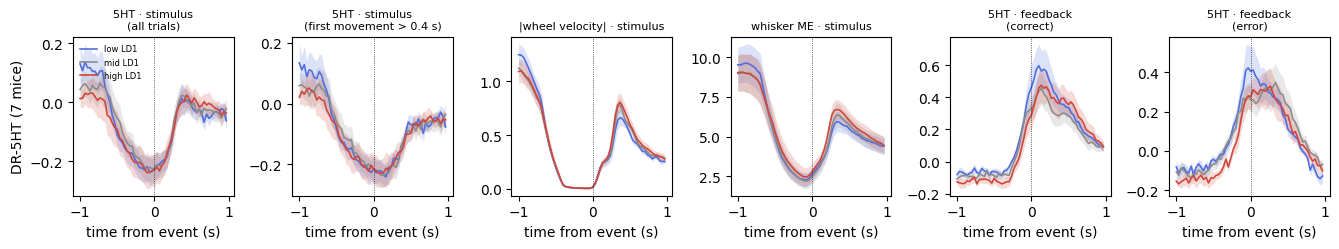

In [6]:
#%%
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import paper_style as ps
TR = L.traces(sorted(T['eid'].unique()))
PANELS = [('stim_all', NM + ' · stimulus\n(all trials)'), ('stim_slow', NM + ' · stimulus\n(first movement > 0.4 s)'),
          ('stim wheel speed', '|wheel velocity| · stimulus'), ('stim whisker ME', 'whisker ME · stimulus'),
          ('fb_correct', NM + ' · feedback\n(correct)'), ('fb_error', NM + ' · feedback\n(error)')]
BIN_COL = [ps.LD1_CMAP(0.08), '0.55', ps.LD1_CMAP(0.92)]
fig, axes = plt.subplots(1, len(PANELS), figsize=(2.25 * len(PANELS), 2.6), sharex=True)
for ax, (key, title) in zip(axes, PANELS):
    t, out = L.binned_traces(T, TR, key, unit='subject')
    for b, (m, se) in out.items():
        ax.plot(t, m, color=BIN_COL[b], lw=1.2, label=['low', 'mid', 'high'][b] + ' LD1')
        ax.fill_between(t, m - se, m + se, color=BIN_COL[b], alpha=0.2, lw=0)
    ax.axvline(0, color='k', lw=0.5, ls=':')
    ax.set_title(title, fontsize=8); ax.set_xlabel('time from event (s)')
axes[0].set_ylabel(f"{TARGET} ({T['subject'].nunique()} mice)")
axes[0].legend(fontsize=6, frameon=False, loc='upper left')
plt.tight_layout()
pathlib.Path('figures').mkdir(exist_ok=True)
fig.savefig('figures/5ht_ld1_traces.png', dpi=250, bbox_inches='tight')
plt.show()

## Reading

- **Session LD1 tracks behaviour only weakly in these mice**: within mouse, paw gating (−0.36, q = 0.003) but not RT
  (−0.14) or accuracy (−0.04) — unlike the DA, ACh and NE mice. So within-mouse LD1 variation in the 5HT cohort is
  less of a behavioural-state axis to begin with.
- **No 5HT measure tracks LD1 after correction** (all q ≥ 0.18; 7 mice, 133 sessions). Nominal: a larger stimulus
  response at high LD1 (+0.21, p = 0.02), also on trials whose movement comes after the window (+0.24, p = 0.01), so
  not movement-locked; it is carried by 5 of the 7 mice. Coupling: nothing (whisking / vigor R² ≈ 0), unlike VTA.
- **Traces**: the thirds overlap; the pre-stimulus level is a little lower at high LD1 and the correct-feedback
  response slightly smaller, both within the SEM.
- Profile agreement with VTA across measures: r = 0.29.

So: a weak, not-significant hint that the 5HT stimulus response is larger in high-LD1 sessions; no coupling change.